In [38]:
from dotenv import load_dotenv
load_dotenv()

import sys
sys.path.append("../streamlit_app")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from utils import load_data
plt.rcParams["figure.figsize"] = (10, 6)
load_data.clear()

df_act = load_data("data/activities_clean.csv")

# --- Filtrage : on exclut les sorties < 1 km (micro-sorties de pollution) ---
df = df_act[df_act["distance_km"] >= 1].copy()
print(f"Filtrage : {len(df_act)} → {len(df)} sorties (drop {len(df_act) - len(df)} micro-sorties)")

# --- Exclusion de la sortie de 35 km non représentative ---
mask_out = df["distance_km"] < 30  # laisse passer jusqu'à 30 km (semi OK, 35 non)
n_before = len(df)
df = df[mask_out].copy()
print(f"Exclusion long trail : {n_before} → {len(df)} sorties")

# --- Age au moment de la sortie ---
BIRTH_DATE = pd.Timestamp("2004-11-15", tz="UTC")
df["date_utc"] = pd.to_datetime(df["start_date_local"], utc=True)
df["age_years"] = (df["date_utc"] - BIRTH_DATE).dt.total_seconds() / (365.25 * 24 * 3600)

# --- Volumes d'entraînement récents ---
df = df.sort_values("date_utc").reset_index(drop=True)
df["date_only"] = df["date_utc"].dt.floor("D").dt.tz_localize(None)

def rolling_backward(dates, values, days, agg="sum"):
    """Pour chaque i, agrège values[j] pour dates[i]-days <= dates[j] < dates[i]."""
    out = np.zeros(len(dates))
    for i in range(len(dates)):
        window_start = dates[i] - pd.Timedelta(days=days)
        mask = (dates.values < dates.values[i]) & (dates.values >= window_start)
        if agg == "sum":
            out[i] = values[mask].sum()
        elif agg == "count":
            out[i] = mask.sum()
    return out

df["vol_7d_km"]    = rolling_backward(df["date_only"], df["distance_km"], 7)
df["vol_30d_km"]   = rolling_backward(df["date_only"], df["distance_km"], 30)
df["vol_90d_km"]   = rolling_backward(df["date_only"], df["distance_km"], 90)
df["n_runs_30d"]   = rolling_backward(df["date_only"], df["distance_km"], 30, agg="count")
df["days_since_last"] = df["date_only"].diff().dt.days.fillna(365)

# Ratio charge aiguë / chronique (attention division par zéro)
df["acwr"] = df["vol_7d_km"] / df["vol_30d_km"].replace(0, np.nan)
df["acwr"] = df["acwr"].fillna(0)

# Quick check
print(df[["date_only", "distance_km", "age_years", "vol_7d_km", "vol_30d_km", "vol_90d_km", "n_runs_30d", "days_since_last"]].tail(10))

# --- Variable dérivée : ratio de pause ---
df["pause_ratio"] = df["pause_seconds"] / df["moving_time_seconds"]

# --- Bins horaires ---
def hour_to_bin(h):
    if 5 <= h < 11: return "matin"
    if 11 <= h < 14: return "midi"
    if 14 <= h < 18: return "aprem"
    if 18 <= h < 22: return "soir"
    return "nuit"
df["hour_bin"] = df["hour"].apply(hour_to_bin)

# --- Nouvelles features à tester ---
# 1. Densité verticale : D+ rapporté à la distance
df["elev_per_km"] = df["total_elevation_gain_m"] / df["distance_km"]

# 2. Heat stress index (approx WBGT simplifié)
df["heat_stress_index"] = df["weather_temperature"] * (1 + df["weather_humidity"] / 100)

# 3. Saison
def month_to_season(m):
    m = int(m)
    if m in [12, 1, 2]:  return "Hiver"
    if m in [3, 4, 5]:   return "Printemps"
    if m in [6, 7, 8]:   return "Été"
    return "Automne"
df["season"] = df["date_utc"].dt.month.apply(month_to_season)

print("Nouvelles features :")
print(df[["elev_per_km", "heat_stress_index"]].describe().round(2).T)
print("\nDistribution des saisons :")
print(df["season"].value_counts())

# --- Variables actives (quanti) ---
ACTIVE = [
    "distance_km", "pace_min_km",
    "elev_per_km",           # remplace total_elevation_gain_m
    "pause_ratio", "pr_count",
    "heat_stress_index",     # remplace weather_temperature + weather_humidity
    "vol_30d_km",
]
# Supplémentaires quanti : suffer_score, age_years, days_since_last, vol_7d_km, vol_90d_km, n_runs_30d, acwr
print(f"\nVariables actives ({len(ACTIVE)}) : {ACTIVE}")
print(f"\nAperçu :")
print(df[ACTIVE].describe().round(2).T)

2026-09-27 14:47:02.001 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Filtrage : 131 → 123 sorties (drop 8 micro-sorties)
Exclusion long trail : 123 → 122 sorties
     date_only  distance_km  age_years  vol_7d_km  vol_30d_km  vol_90d_km  \
112 2026-08-26       1.8878  21.778148     1.1947     21.8971     54.5678   
113 2026-08-26       5.0071  21.779191     1.1947     21.8971     54.5678   
114 2026-08-27       2.4231  21.781728     8.0896     28.7920     61.4627   
115 2026-08-29       1.9247  21.786569    10.5127     31.2151     63.8858   
116 2026-08-30       2.4712  21.789085    12.4374     33.1398     65.8105   
117 2026-08-31       1.8439  21.792769    14.9086     35.6110     68.2817   
118 2026-09-03       4.1151  21.799977     8.6629     37.4549     70.1256   
119 2026-09-09       2.6225  21.817375     4.1151     31.5618     65.5717   
120 2026-09-20       2.5019  21.846629     0.0000     23.4901     68.1942   
121 2026-09-22       6.6018  21.852199     2.5019     25.9920     70.6961   

     n_runs_30d  days_since_last  
112         5.0         

# ACP normée : calcul + éboulis

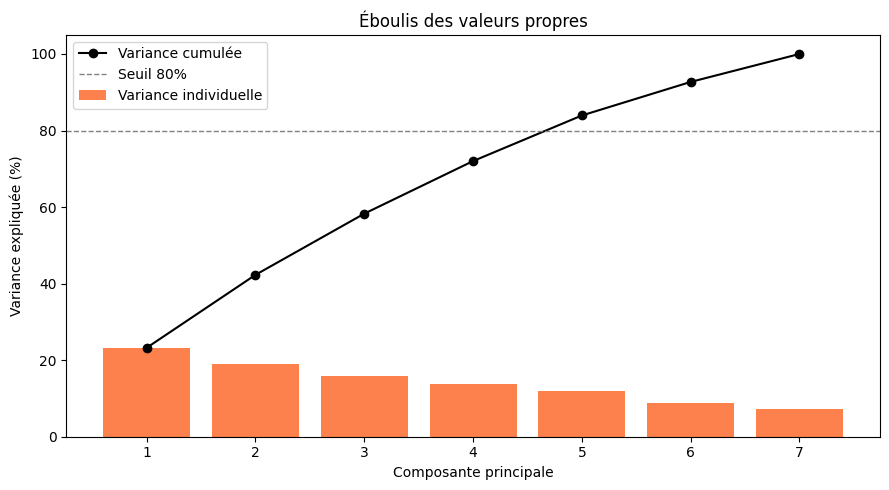

Variance expliquée par axe :
  PC1 :  23.2%  (cumul  23.2%)
  PC2 :  19.1%  (cumul  42.3%)
  PC3 :  16.0%  (cumul  58.3%)
  PC4 :  13.7%  (cumul  72.0%)
  PC5 :  11.9%  (cumul  83.9%)
  PC6 :   8.8%  (cumul  92.7%)
  PC7 :   7.3%  (cumul 100.0%)


In [39]:
X = df[ACTIVE].values
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

pca = PCA()
X_pca = pca.fit_transform(X_std)

# Variance expliquée
var_exp = pca.explained_variance_ratio_ * 100
var_cum = np.cumsum(var_exp)

# Éboulis
fig, ax = plt.subplots(figsize=(9, 5))
axes_x = np.arange(1, len(var_exp) + 1)
ax.bar(axes_x, var_exp, color="#FC4C02", alpha=0.7, label="Variance individuelle")
ax.plot(axes_x, var_cum, "ko-", label="Variance cumulée")
ax.axhline(80, color="grey", linestyle="--", linewidth=1, label="Seuil 80%")
ax.set_xlabel("Composante principale")
ax.set_ylabel("Variance expliquée (%)")
ax.set_title("Éboulis des valeurs propres")
ax.set_xticks(axes_x)
ax.legend()
plt.tight_layout()
plt.show()

print("Variance expliquée par axe :")
for i, (v, c) in enumerate(zip(var_exp, var_cum), 1):
    print(f"  PC{i} : {v:5.1f}%  (cumul {c:5.1f}%)")

Cercle des corrélations

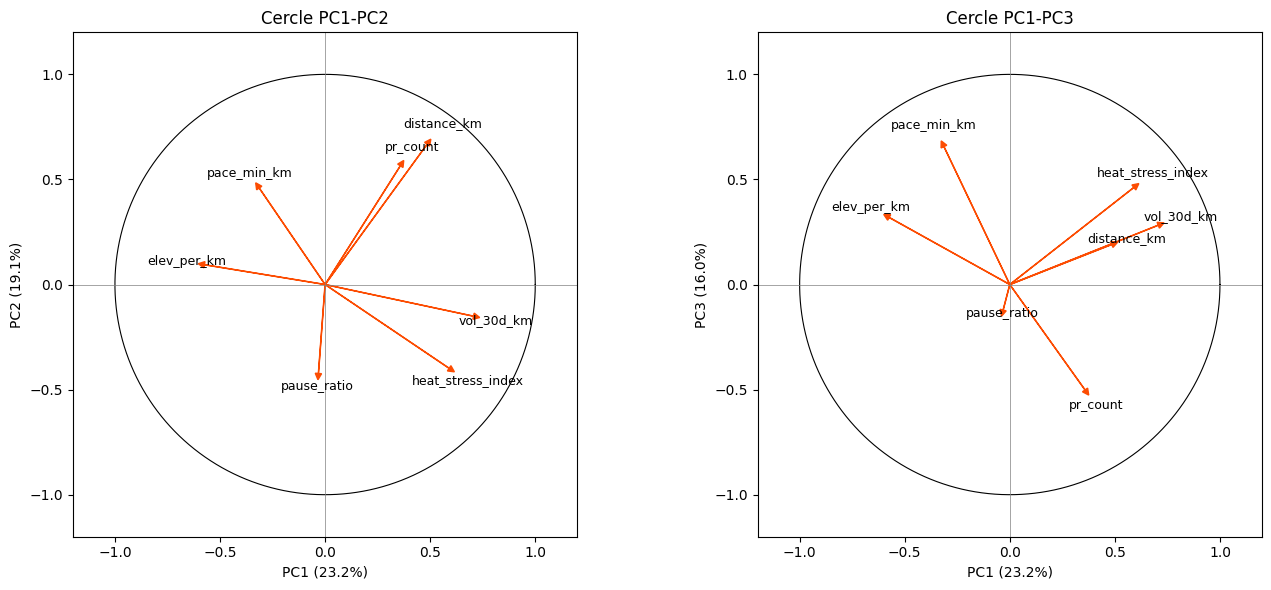


Contributions (loadings) :
                    PC1   PC2   PC3
distance_km        0.49  0.67  0.19
pace_min_km       -0.31  0.46  0.66
elev_per_km       -0.57  0.09  0.32
pause_ratio       -0.03 -0.42 -0.12
pr_count           0.36  0.56 -0.50
heat_stress_index  0.59 -0.40  0.46
vol_30d_km         0.71 -0.15  0.28


In [40]:
# Corrélations variables ↔ composantes = loadings * sqrt(eigenvalue)
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

def plot_correlation_circle(ax, axis_x, axis_y, var_exp):
    theta = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(theta), np.sin(theta), "k-", linewidth=0.8)
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    for i, var in enumerate(ACTIVE):
        x, y = loadings[i, axis_x], loadings[i, axis_y]
        ax.arrow(0, 0, x, y, head_width=0.03, head_length=0.03, fc="#FC4C02", ec="#FC4C02")
        ax.text(x * 1.15, y * 1.15, var, ha="center", va="center", fontsize=9)
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect("equal")
    ax.set_xlabel(f"PC{axis_x+1} ({var_exp[axis_x]:.1f}%)")
    ax.set_ylabel(f"PC{axis_y+1} ({var_exp[axis_y]:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_correlation_circle(axes[0], 0, 1, var_exp)
axes[0].set_title("Cercle PC1-PC2")
plot_correlation_circle(axes[1], 0, 2, var_exp)
axes[1].set_title("Cercle PC1-PC3")
plt.tight_layout()
plt.show()

# Tableau des loadings
print("\nContributions (loadings) :")
print(pd.DataFrame(
    loadings[:, :3],
    columns=["PC1", "PC2", "PC3"],
    index=ACTIVE
).round(2))

# Plan factoriel des individus

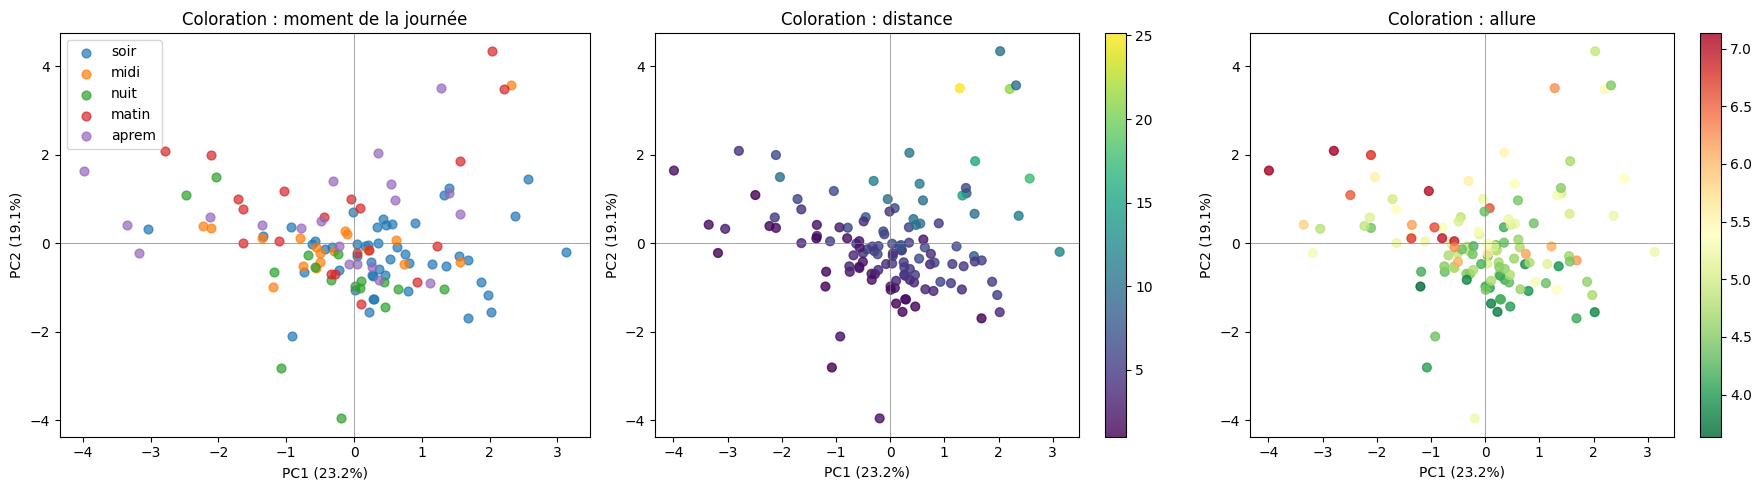

In [41]:
# On récupère les scores + on rejoint les qualis pour la coloration
scores = pd.DataFrame(X_pca[:, :3], columns=["PC1", "PC2", "PC3"], index=df.index)
scores = scores.join(df[["day_of_week", "month", "hour_bin", "weather_code",
                          "distance_km", "pace_min_km", "suffer_score"]])
scores["month_str"] = scores["month"].astype(str)

# 3 colorations pour tester des séparations différentes
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Par tranche horaire
for hb in scores["hour_bin"].unique():
    sub = scores[scores["hour_bin"] == hb]
    axes[0].scatter(sub["PC1"], sub["PC2"], alpha=0.7, s=40, label=hb)
axes[0].set_xlabel(f"PC1 ({var_exp[0]:.1f}%)")
axes[0].set_ylabel(f"PC2 ({var_exp[1]:.1f}%)")
axes[0].set_title("Coloration : moment de la journée")
axes[0].axhline(0, color="grey", linewidth=0.5)
axes[0].axvline(0, color="grey", linewidth=0.5)
axes[0].legend()

# Par distance (continue)
sc = axes[1].scatter(scores["PC1"], scores["PC2"], c=scores["distance_km"],
                     cmap="viridis", s=40, alpha=0.8)
axes[1].set_xlabel(f"PC1 ({var_exp[0]:.1f}%)")
axes[1].set_ylabel(f"PC2 ({var_exp[1]:.1f}%)")
axes[1].set_title("Coloration : distance")
axes[1].axhline(0, color="grey", linewidth=0.5)
axes[1].axvline(0, color="grey", linewidth=0.5)
plt.colorbar(sc, ax=axes[1])

# Par allure
sc = axes[2].scatter(scores["PC1"], scores["PC2"], c=scores["pace_min_km"],
                     cmap="RdYlGn_r", s=40, alpha=0.8)
axes[2].set_xlabel(f"PC1 ({var_exp[0]:.1f}%)")
axes[2].set_ylabel(f"PC2 ({var_exp[1]:.1f}%)")
axes[2].set_title("Coloration : allure")
axes[2].axhline(0, color="grey", linewidth=0.5)
axes[2].axvline(0, color="grey", linewidth=0.5)
plt.colorbar(sc, ax=axes[2])

plt.tight_layout()
plt.show()

# Projeter les qualis en supplémentaires (centroïdes par catégorie)

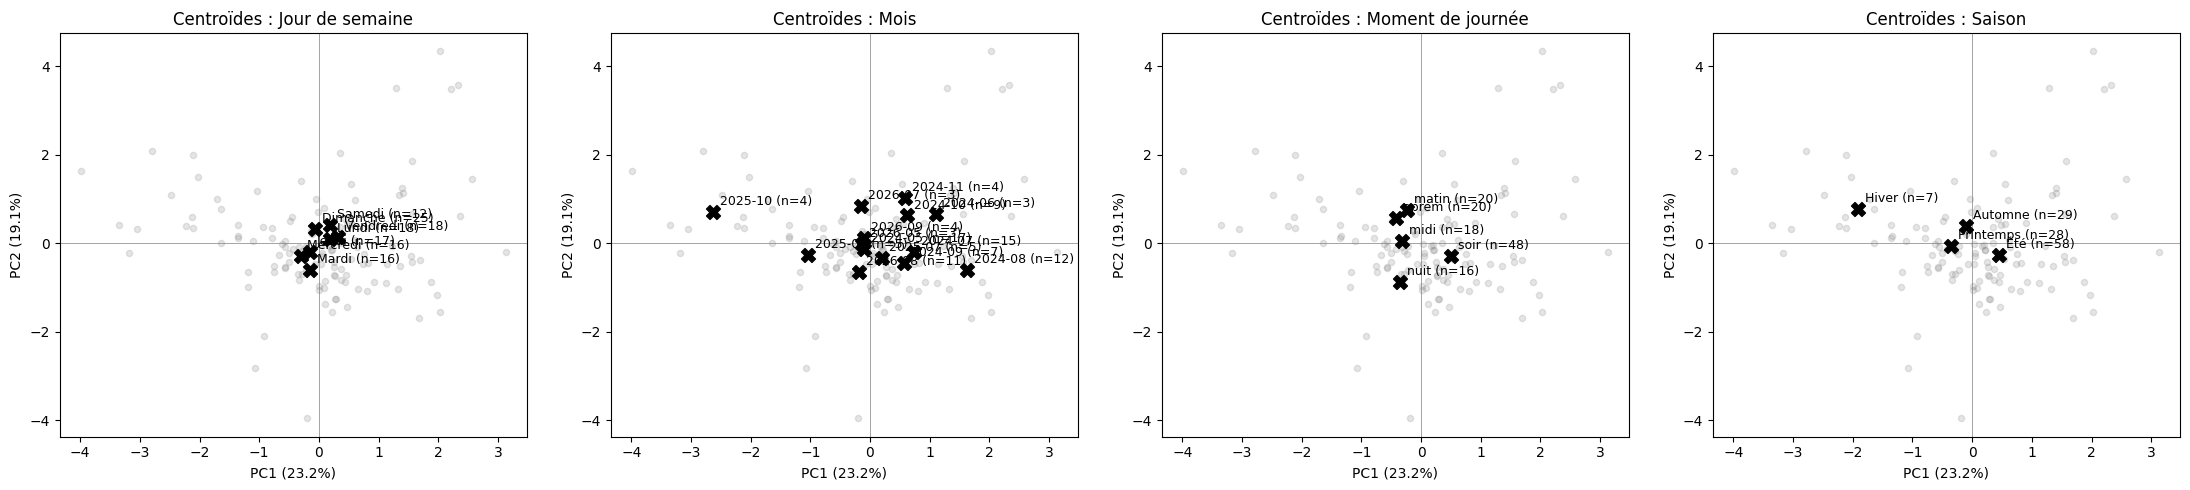

In [42]:
df["month_str"] = df["month"].astype(str)

# Centroïdes des modalités qualitatives sur PC1-PC2
def plot_quali_centroids(ax, quali_col, top_n=None):
    for mod in df[quali_col].dropna().unique():
        mask = df[quali_col] == mod
        cx = X_pca[mask.values, 0].mean()
        cy = X_pca[mask.values, 1].mean()
        n = mask.sum()
        if top_n and n < top_n:
            continue
        ax.scatter(cx, cy, s=100, marker="X", color="black", zorder=5)
        ax.annotate(f"{mod} (n={n})", (cx, cy), fontsize=9,
                    xytext=(5, 5), textcoords="offset points")

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, col, title in zip(
    axes,
    ["day_of_week", "month_str", "hour_bin", "season"],
    ["Jour de semaine", "Mois", "Moment de journée", "Saison"]
):
    ax.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.2, s=20, color="grey")
    plot_quali_centroids(ax, col, top_n=3)
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}%)")
    ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}%)")
    ax.set_title(f"Centroïdes : {title}")
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
plt.tight_layout()
plt.show()

# Projeter suffer_score comme supplémentaire quanti

In [43]:
# Corrélation suffer_score ↔ PCs
sub_valid = df["suffer_score"].dropna()
scores_valid = X_pca[df["suffer_score"].notna().values]

correlations = [np.corrcoef(sub_valid, scores_valid[:, i])[0, 1] for i in range(7)]
print("Corrélation suffer_score ↔ chaque PC :")
for i, c in enumerate(correlations):
    print(f"  PC{i+1} : {c:+.3f}")

Corrélation suffer_score ↔ chaque PC :
  PC1 : +0.390
  PC2 : +0.602
  PC3 : +0.051
  PC4 : +0.137
  PC5 : +0.050
  PC6 : -0.286
  PC7 : +0.411
